In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap
import random
import heapq
import time
from collections import deque

random.seed(42)
np.random.seed(42)

In [16]:
def generate_maze(rows, cols):
    if rows % 2 == 0:
        rows += 1
    if cols % 2 == 0:
        cols += 1
    
    maze = np.ones((rows, cols), dtype=int)
    
    start_r = random.randrange(1, rows, 2)
    start_c = random.randrange(1, cols, 2)
    maze[start_r, start_c] = 0  # Mark as passage
    
    walls = []
    
    def add_walls(r, c):
        directions = [(0, 2), (0, -2), (2, 0), (-2, 0)] 
        for dr, dc in directions:
            nr, nc = r + dr, c + dc
            if 1 <= nr < rows-1 and 1 <= nc < cols-1: 
                if maze[nr, nc] == 1: 
                    walls.append((r, c, nr, nc))
    
    add_walls(start_r, start_c)
    
    while walls:
        wall_idx = random.randint(0, len(walls) - 1)
        r1, c1, r2, c2 = walls.pop(wall_idx)
        
        if maze[r2, c2] == 1:
            adjacent_passages = 0
            for dr, dc in [(0, 2), (0, -2), (2, 0), (-2, 0)]:
                nr, nc = r2 + dr, c2 + dc
                if 0 <= nr < rows and 0 <= nc < cols and maze[nr, nc] == 0:
                    adjacent_passages += 1
            
            if adjacent_passages == 1: 
                mid_r = (r1 + r2) // 2
                mid_c = (c1 + c2) // 2
                maze[mid_r, mid_c] = 0
                
                maze[r2, c2] = 0
                
                add_walls(r2, c2)
    
    return maze

In [17]:
def place_start_goal(maze):
    rows, cols = maze.shape
    maze_copy = maze.copy()
    
    start_pos = (1, 1)
    if maze_copy[start_pos] == 0:
        maze_copy[start_pos] = 2 
    else:
        for r in range(1, rows, 2):
            for c in range(1, cols, 2):
                if maze_copy[r, c] == 0:
                    maze_copy[r, c] = 2
                    start_pos = (r, c)
                    break
            if maze_copy[start_pos] == 2:
                break
    
    goal_pos = (rows-2, cols-2)
    if maze_copy[goal_pos] == 0:
        maze_copy[goal_pos] = 3  # Goal = 3
    else:
        for r in range(rows-2, 0, -2):
            for c in range(cols-2, 0, -2):
                if maze_copy[r, c] == 0:
                    maze_copy[r, c] = 3
                    goal_pos = (r, c)
                    break
            if maze_copy[goal_pos] == 3:
                break
    
    return maze_copy, start_pos, goal_pos

In [18]:
def get_neighbors(r, c, maze):
    rows, cols = maze.shape
    neighbors = []
    directions = [(0, 1), (0, -1), (1, 0), (-1, 0)] 
    
    for dr, dc in directions:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and maze[nr, nc] != 1:  
            neighbors.append((nr, nc))
    
    return neighbors

def manhattan_distance(p1, p2):
    return abs(p1[0] - p2[0]) + abs(p1[1] - p2[1])

In [19]:
def plot_maze(maze, title="Maze"):
    colors = ['white', 'black', 'orange', 'red', 'green', 'blue']
    cmap = ListedColormap(colors)
    
    plt.figure(figsize=(10, 10))
    plt.imshow(maze, cmap=cmap, vmin=0, vmax=5)
    plt.title(title, fontsize=16)
    
    # Add legend
    import matplotlib.patches as mpatches
    legend_elements = [
        mpatches.Patch(color='white', label='Path'),
        mpatches.Patch(color='black', label='Wall'),
        mpatches.Patch(color='orange', label='Start'),
        mpatches.Patch(color='red', label='Goal'),
        mpatches.Patch(color='green', label='Visited'),
        mpatches.Patch(color='blue', label='Final Path')
    ]
    plt.legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def animate_search(search_steps, title="A* Search Animation"):
    if not search_steps:
        print("No search steps to animate!")
        return
    
    colors = ['white', 'black', 'orange', 'red', 'green', 'blue']
    cmap = ListedColormap(colors)
    
    fig, ax = plt.subplots(figsize=(10, 10))
    
    def animate(frame):
        ax.clear()
        maze = search_steps[frame]['maze']
        current = search_steps[frame]['current']
        
        ax.imshow(maze, cmap=cmap, vmin=0, vmax=5)
        ax.set_title(f"{title} - Step {frame + 1}/{len(search_steps)}")
        
        # Highlight current position
        ax.plot(current[1], current[0], 'yo', markersize=10, markeredgecolor='black')
        
        ax.grid(True, alpha=0.3)
        ax.set_xticks(range(maze.shape[1]))
        ax.set_yticks(range(maze.shape[0]))
    
    anim = animation.FuncAnimation(fig, animate, frames=len(search_steps), 
                                 interval=200, repeat=True)
    plt.tight_layout()
    plt.show()
    
    return anim

In [20]:
generated_maze = generate_maze(21, 21)

In [21]:
maze_with_sg, start_pos, goal_pos = place_start_goal(generated_maze)

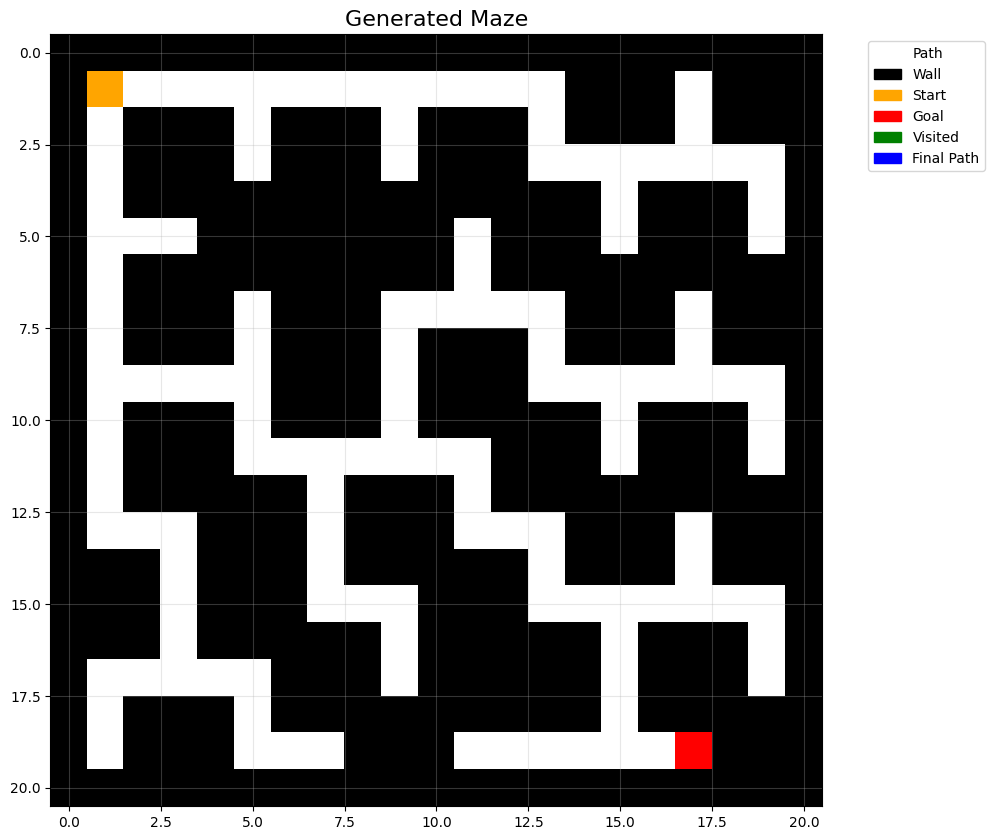

In [22]:
plot_maze(maze_with_sg, "Generated Maze")

In [23]:
def a_star_search(maze, start, goal):
    start_time = time.time()
    
    maze_final = maze.copy()
    
    heap = [(0, 0, start, [start])]
    
    visited = set()
    g_costs = {start: 0} 
    search_steps = []  
    
    nodes_visited = 0
    
    while heap:
        f_cost, g_cost, current, path = heapq.heappop(heap)
        
        if current in visited:
            continue
            
        visited.add(current)
        nodes_visited += 1
        
        if current != start and current != goal:
            maze_final[current] = 4 
        
        search_steps.append({
            'maze': maze_final.copy(),
            'current': current,
            'path': path.copy()
        })
        if current == goal:
            final_maze = maze_final.copy()
            for pos in path:
                if pos != start and pos != goal:
                    final_maze[pos] = 5  
            end_time = time.time()
            
            stats = {
                'nodes_visited': nodes_visited,
                'path_length': len(path),
                'execution_time': end_time - start_time
            }
            
            return path, final_maze, search_steps, stats
        
        for neighbor in get_neighbors(current[0], current[1], maze):
            if neighbor in visited:
                continue
                
            rand_g = g_cost + 1  
            
            if neighbor not in g_costs or rand_g < g_costs[neighbor]:
                g_costs[neighbor] = rand_g
                h_cost = manhattan_distance(neighbor, goal)
                f_cost = rand_g + h_cost
                
                new_path = path + [neighbor]
                heapq.heappush(heap, (f_cost, rand_g, neighbor, new_path))
    
    end_time = time.time()
    stats = {
        'nodes_visited': nodes_visited,
        'path_length': 0,
        'execution_time': end_time - start_time
    }
    
    return [], maze_final, search_steps, stats

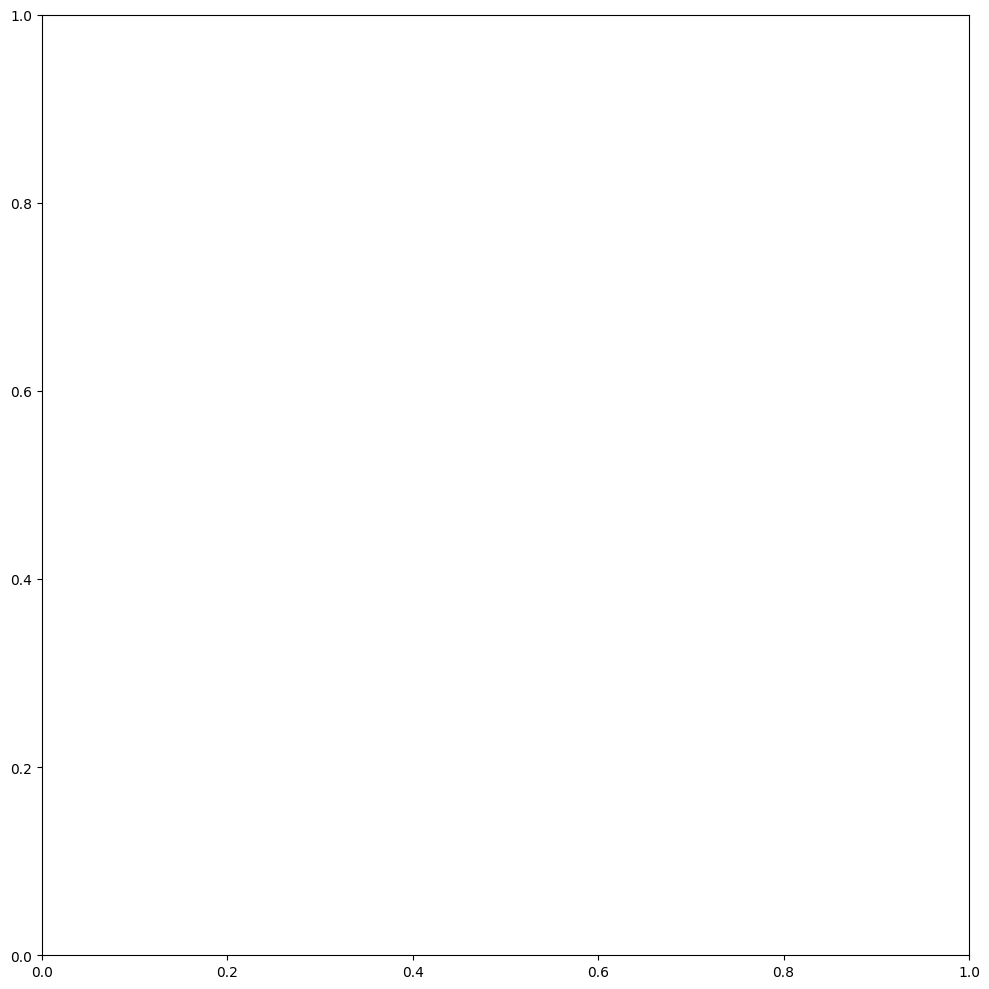

/home/kree/miniconda3/envs/ML_SIG/lib/python3.13/site-packages/matplotlib/animation.py:908: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


In [31]:
path, final_maze, search_steps, stats = a_star_search(maze_with_sg, start_pos, goal_pos)
anim = animate_search(search_steps, title="A* Search Animation")
anim.save('a_star_search_animation.mp4', writer='ffmpeg', fps=2)

path found: True
path length: 35
nodes visited: 87
execution time: 0.0018 seconds
path: [(1, 1), (2, 1), (3, 1), (4, 1), (5, 1), (6, 1), (7, 1), (8, 1), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (10, 5), (11, 5), (11, 6), (11, 7), (11, 8), (11, 9), (11, 10), (11, 11), (12, 11), (13, 11), (13, 12), (13, 13), (14, 13), (15, 13), (15, 14), (15, 15), (16, 15), (17, 15), (18, 15), (19, 15), (19, 16), (19, 17)]


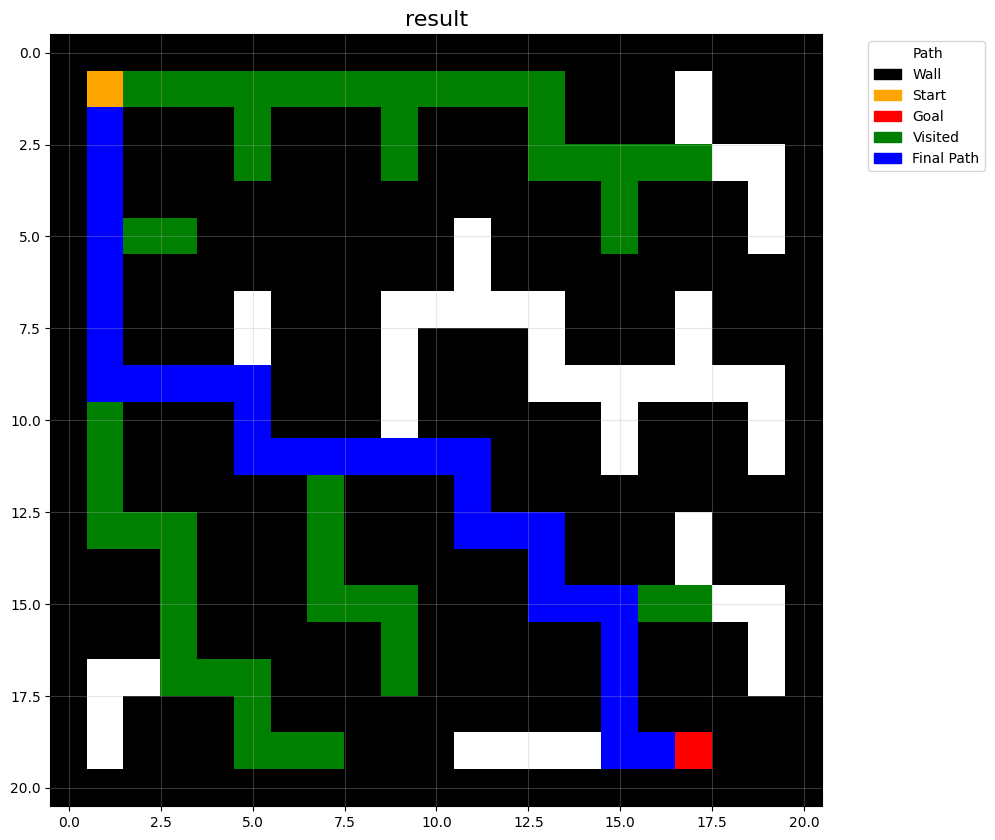

In [25]:
path, final_maze, search_steps, stats = a_star_search(maze_with_sg, start_pos, goal_pos)


print(f"path found: {'True' if path else 'False'}")
print(f"path length: {stats['path_length']}")
print(f"nodes visited: {stats['nodes_visited']}")
print(f"execution time: {stats['execution_time']:.4f} seconds")

if path:
    print(f"path: {path}")

plot_maze(final_maze, "result")

In [28]:
import pygame
import time

# Define color mapping
COLOR_MAP = {
    0: (255, 255, 255),  # path
    1: (0, 0, 0),        # wall
    2: (255, 165, 0),    # start
    3: (255, 0, 0),      # goal
    4: (0, 255, 0),      # visited
    5: (0, 0, 255),      # final path
}

def draw_maze(screen, maze, current, cell_size):
    for row in range(maze.shape[0]):
        for col in range(maze.shape[1]):
            value = maze[row, col]
            color = COLOR_MAP.get(value, (200, 200, 200))
            rect = pygame.Rect(col * cell_size, row * cell_size, cell_size, cell_size)
            pygame.draw.rect(screen, color, rect)
            pygame.draw.rect(screen, (180, 180, 180), rect, 1)  # grid lines
    if current:
        pygame.draw.circle(screen, (255, 255, 0), 
            (current[1]*cell_size + cell_size//2, current[0]*cell_size + cell_size//2), 
            cell_size//3)

def run_pygame_visualization(search_steps, maze_shape):
    pygame.init()
    cell_size = 25
    width, height = maze_shape[1] * cell_size, maze_shape[0] * cell_size
    screen = pygame.display.set_mode((width, height + 50))
    pygame.display.set_caption("A* Maze Visualizer")

    font = pygame.font.SysFont(None, 36)
    button = pygame.Rect(width//2 - 50, height + 10, 100, 30)

    running = True
    started = False
    step_index = 0
    clock = pygame.time.Clock()

    while running:
        screen.fill((255, 255, 255))
        pygame.draw.rect(screen, (0, 128, 0), button)
        text = font.render("Start", True, (255, 255, 255))
        screen.blit(text, (button.x + 15, button.y + 2))

        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                running = False
            if event.type == pygame.MOUSEBUTTONDOWN:
                if button.collidepoint(event.pos):
                    started = True

        if started and step_index < len(search_steps):
            maze = search_steps[step_index]['maze']
            current = search_steps[step_index]['current']
            draw_maze(screen, maze, current, cell_size)
            step_index += 1
            pygame.time.wait(50)  # delay between steps
        elif not started:
            draw_maze(screen, search_steps[0]['maze'], None, cell_size)
        else:
            draw_maze(screen, search_steps[-1]['maze'], None, cell_size)

        pygame.display.flip()
        clock.tick(60)

    pygame.quit()


In [29]:
run_pygame_visualization(search_steps, maze_with_sg.shape)